# Exploratory_Data_Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# import dataset
date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']

order_items_date_columns = ['shipping_limit_date']

orders_cleaned      = pd.read_csv('../data/interim/olist_orders_cleaned.csv', parse_dates=date_cols)
order_items_cleaned = pd.read_csv('../data/interim/olist_order_items_cleaned.csv', parse_dates=order_items_date_columns)
customers_cleaned   = pd.read_csv('../data/interim/olist_customers_cleaned.csv')
payments_cleaned    = pd.read_csv('../data/interim/olist_ payments_cleaned.csv')
products_cleaned    = pd.read_csv('../data/interim/olist_products_cleaned.csv')
translation_cleaned = pd.read_csv('../data/interim/olist_ translation_cleaned.csv')
geolocation_cleaned = pd.read_csv('../data/interim/olist_geolocation_cleaned.csv')
reviews_cleaned     = pd.read_csv('../data/interim/olist_ reviews_cleaned.csv')
sellers_cleaned     = pd.read_csv('../data/interim/olist_sellers_cleaned.csv')

# EDA-01 — Univariate Analysis

## Orders Analysis

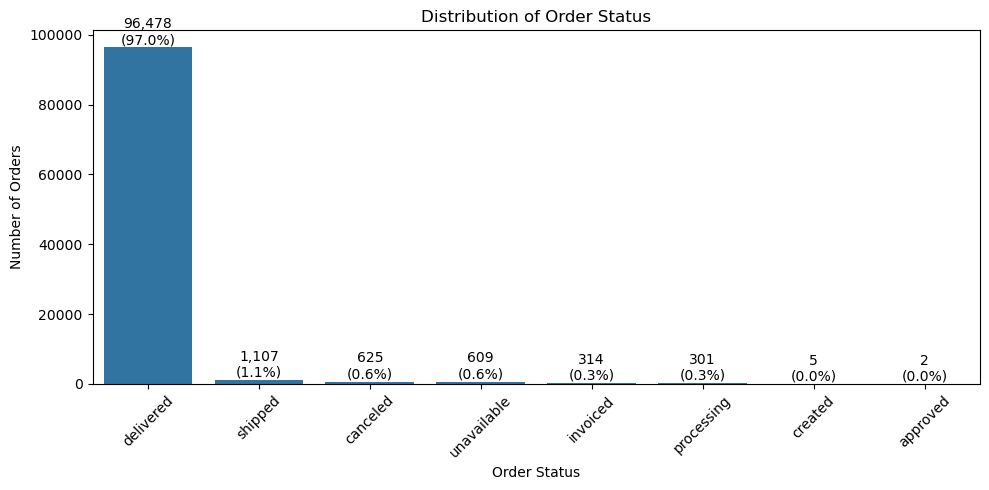

In [3]:
order_status_counts = orders_cleaned["order_status"].value_counts()
total_orders = order_status_counts.sum()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=order_status_counts.index,
    y=order_status_counts.values
    
)

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

# Add count and percentage labels
for bar in ax.patches:
    count = bar.get_height()
    percentage = (count / total_orders) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{int(count):,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

#### Key Insights

- The 97% of orders have a `delivered` status, indicating that most orders in the dataset were successfully completed.
- `shipped` and `canceled` orders represent a much smaller share of the total order volume.

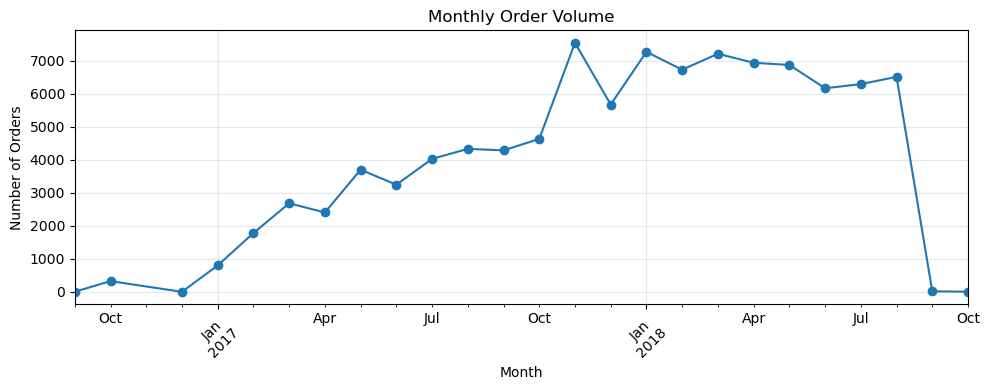

In [4]:
monthly_orders = (
    orders_cleaned.groupby(orders_cleaned['order_purchase_timestamp'].dt.to_period("M")).size()
    )
monthly_orders

plt.figure(figsize=(10, 4))

monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Key Insights

- Monthly order volume shows a clear growth trend during the earlier part of the observed period.
- Order volume reached its highest level toward the later part of the main growth period.
- A noticeable decline appears near the end of the observation period . the decline may be influenced by incomplete observations in the final period.

In [5]:
valid_orders = orders_cleaned[orders_cleaned['purchase_to_customer_hours'] >= 0]
to_days = (valid_orders['purchase_to_customer_hours'] / 24)

to_days.agg(['min', 'mean', 'median','max'])

min         0.533414
mean       12.558702
median     10.217755
max       209.628611
Name: purchase_to_customer_hours, dtype: float64

In [6]:
to_days.describe(percentiles=[.25, .5, .75, .9, .95])

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
90%         23.097604
95%         29.276016
max        209.628611
Name: purchase_to_customer_hours, dtype: float64

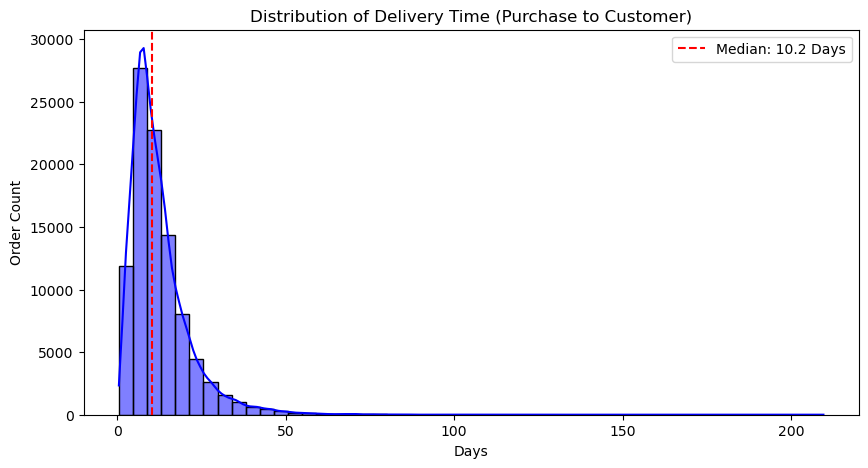

In [7]:
plt.figure(figsize=(10, 5))
sns.histplot(to_days, kde=True, bins=50, color='blue')
plt.title('Distribution of Delivery Time (Purchase to Customer)')
plt.xlabel('Days')
plt.ylabel('Order Count')
plt.axvline(to_days.median(), color='red', linestyle='--', label=f'Median: {to_days.median():.1f} Days')
plt.legend()
plt.show()

 #### Key Observation
Delivery time distribution is right-skewed, with most orders concentrated at shorter delivery times and a smaller number of orders taking considerably longer.

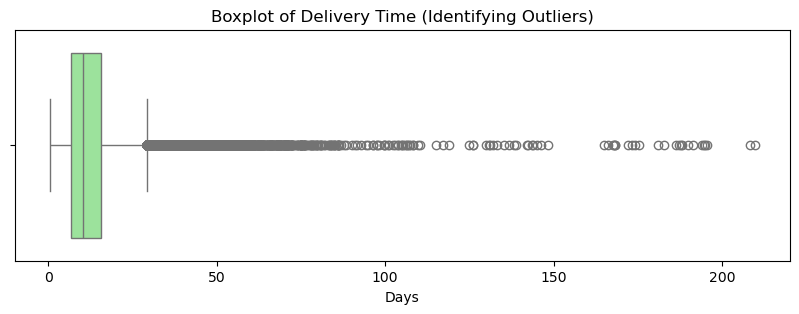

In [8]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=to_days, color='lightgreen')
plt.title('Boxplot of Delivery Time (Identifying Outliers)')
plt.xlabel('Days')
plt.show()

#### Key Observation

- The boxplot confirms the presence of a right-skewed distribution and several high-duration outliers.
- These outliers represent unusually long delivery times and were retained because they may reflect real business cases.

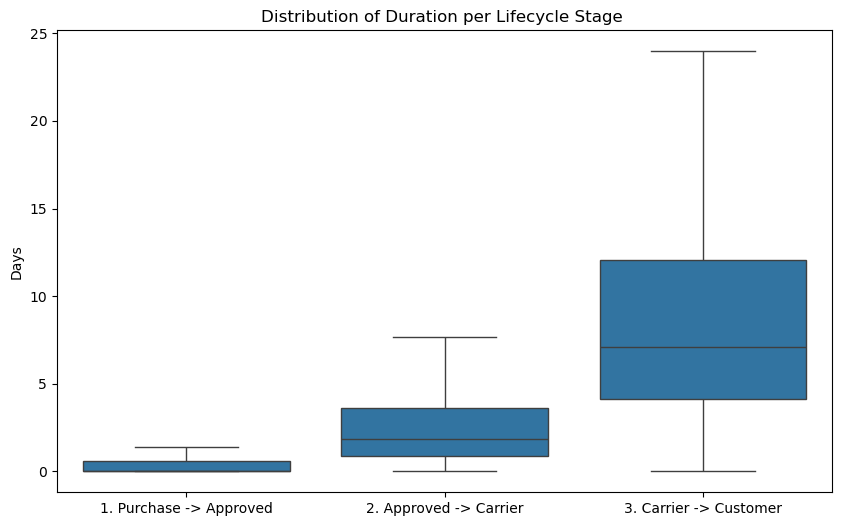

In [9]:
valid_lifecycle = orders_cleaned[
    (orders_cleaned['purchase_to_approved_hours'] >= 0) &
    (orders_cleaned['approval_to_carrier_hours'] >= 0) &
    (orders_cleaned['carrier_to_customer_hours'] >= 0)
]

lifecycle_long = pd.DataFrame({
    '1. Purchase -> Approved': valid_lifecycle['purchase_to_approved_hours'] / 24,
    '2. Approved -> Carrier': valid_lifecycle['approval_to_carrier_hours'] / 24,
    '3. Carrier -> Customer': valid_lifecycle['carrier_to_customer_hours'] / 24
}).melt(var_name='Stage', value_name='Days')

plt.figure(figsize=(10, 6))
sns.boxplot(data=lifecycle_long, x='Stage', y='Days', showfliers=False)
plt.title('Distribution of Duration per Lifecycle Stage ')
plt.ylabel('Days')
plt.xlabel('')
plt.show()

#### Key Observation
Carrier → Customer has the highest median duration and therefore represents the longest stage of the observed order lifecycle.

In [10]:
## 4. Delivery Performance

delivered_valid = orders_cleaned[
    (orders_cleaned['order_delivered_customer_date'].notna())
].copy()

delivered_valid['is_on_time'] = (
    delivered_valid['order_delivered_customer_date'] <= delivered_valid['order_estimated_delivery_date']
)

In [11]:
on_time_rate = delivered_valid['is_on_time'].mean() * 100
print(f"on time rate :  {on_time_rate:.2f}%")
print(f"total orders : {len(delivered_valid)}")

on time rate :  91.89%
total orders : 96476


#### Key Insights

- Approximately 91.89% of delivered orders were delivered on or before the estimated delivery date.
- This indicates that the majority of orders were delivered within the promised timeframe.
- However, approximately 8.11% of delivered orders were delivered after the estimated date, indicating that late delivery remains a relevant operational issue.
- The overall on-time delivery rate provides a high-level view of delivery performance, but it does not explain the causes of late deliveries.

## Order Items Analysis

### How are item prices distributed?

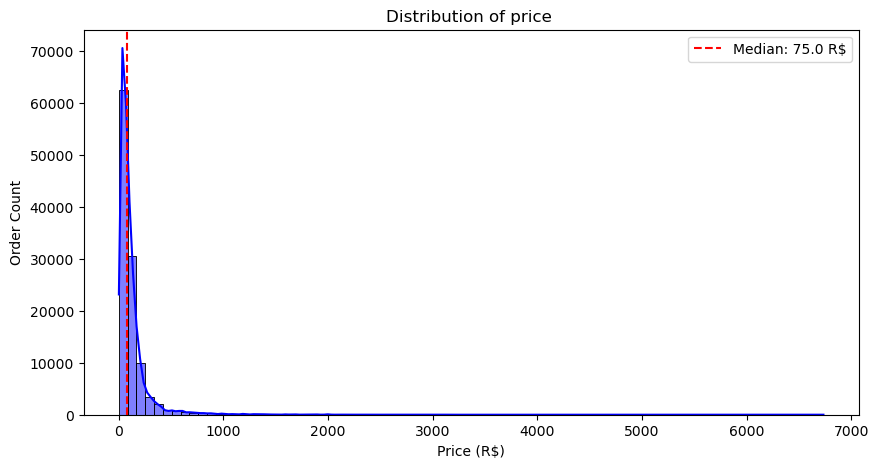

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
90%         229.800000
95%         349.900000
max        6735.000000
Name: price, dtype: float64

In [12]:
peice_dis = order_items_cleaned['price']
plt.figure(figsize=(10, 5))
sns.histplot(peice_dis, kde=True, bins=80, color='blue')
plt.title('Distribution of price ')
plt.xlabel('Price (R$)')
plt.ylabel('Order Count')
plt.axvline(peice_dis.median(), color='red', linestyle='--', label=f'Median: {peice_dis.median():.1f} R$')
plt.legend()
plt.show()

order_items_cleaned['price'].describe(
    percentiles=[.25, .5, .75, .9, .95]
)

#### Key Observation

- The mean item price is substantially higher than the median, and the distribution is positively skewed.
- Most items are concentrated at relatively lower price levels, while a smaller number of high-priced items create a long right tail.

### How are freight costs distributed?

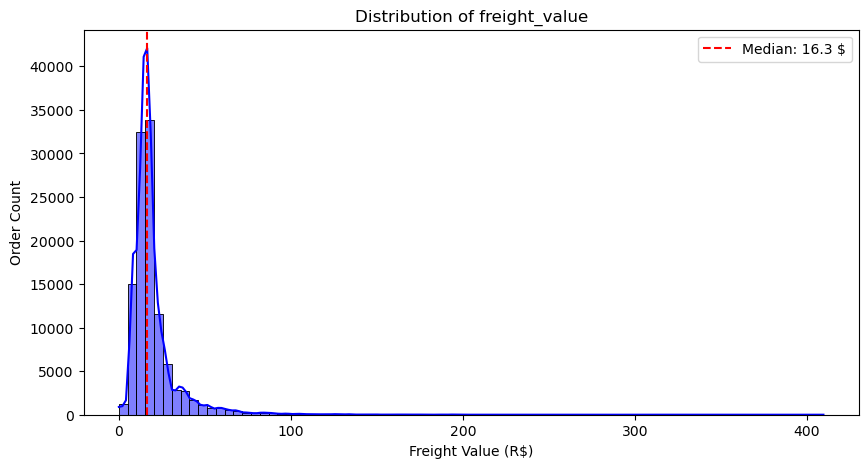

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
90%          34.041000
95%          45.120000
max         409.680000
Name: freight_value, dtype: float64

In [13]:
freight_value_dis = order_items_cleaned['freight_value']
plt.figure(figsize=(10, 5))
sns.histplot(freight_value_dis, kde=True, bins=80, color='blue')
plt.title('Distribution of freight_value')
plt.xlabel('Freight Value (R$)')
plt.ylabel('Order Count')
plt.axvline(freight_value_dis.median(), color='red', linestyle='--', label=f'Median: {freight_value_dis.median():.1f} $')
plt.legend()
plt.show()

order_items_cleaned['freight_value'].describe(
    percentiles=[.25, .5, .75, .9, .95]
)

In [14]:
zero_freight = (order_items_cleaned['freight_value'] == 0).sum()

zero_freight_pct = (
    zero_freight / len(order_items_cleaned) * 100
)

print(f"Zero freight items: {zero_freight:,}")
print(f"Percentage: {zero_freight_pct:.2f}%")

Zero freight items: 383
Percentage: 0.34%


#### key observation 

- 383 of the order items have 0 shipping costs, which is likely due to proximity or discounts.

### How many items do customers typically purchase per order?

In [15]:
items_per_order = (
    order_items_cleaned
    .groupby('order_id')['order_item_id']
    .max()
)

items_per_order.describe(percentiles=[.25, .5, .75, .9, .95])

count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
90%          1.000000
95%          2.000000
max         21.000000
Name: order_item_id, dtype: float64

#### Key Observations

- Most orders contain a single item, as the median number of items per order is 1.
- At least 90% of orders contain only one item.

### Is item price associated with freight value?

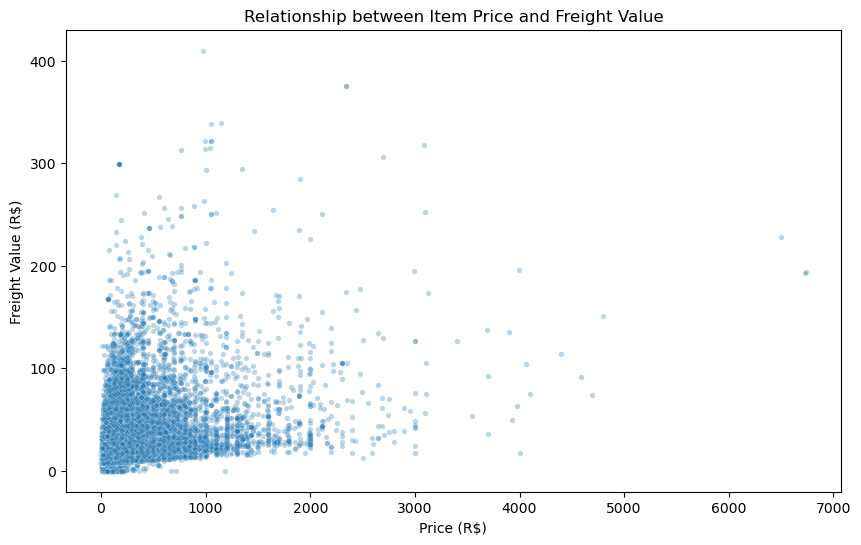

np.float64(0.434190324041091)

In [16]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=order_items_cleaned, x='price', y='freight_value', alpha=0.3, s=15)
plt.title('Relationship between Item Price and Freight Value')
plt.xlabel('Price (R$)')
plt.ylabel('Freight Value (R$)')
plt.show()

correlation_spearman = order_items_cleaned['price'].corr(order_items_cleaned['freight_value'], method='spearman')
correlation_spearman

#### Key Observations

- A moderate positive monotonic relationship exists between item price and freight value (Spearman ρ = 0.434).
- Higher-priced items tend to be associated with higher freight values, but the relationship is not strong enough to explain freight costs by price alone.
- The wide dispersion of freight values at similar price levels suggests that other factors may also be associated with shipping costs.

### How significant is freight cost relative to item price?

In [17]:
order_items_cleaned['freight_ratio'] = (
    order_items_cleaned['freight_value']
    / order_items_cleaned['price']
)
order_items_cleaned['freight_ratio'].describe(
    percentiles=[.5, .75, .9, .95]
)

count    112650.000000
mean          0.320864
std           0.349894
min           0.000000
50%           0.231356
75%           0.393036
90%           0.642857
95%           0.874702
max          26.235294
Name: freight_ratio, dtype: float64

## Customers Analysis

### What percentage of customers have placed more than one order?

In [18]:
orders_per_customer = (
    customers_cleaned
    .groupby('customer_unique_id')
    .size()
)

orders_per_customer.describe(
    percentiles=[.5, .75, .9, .95, .99]
)


count    96096.000000
mean         1.034809
std          0.214384
min          1.000000
50%          1.000000
75%          1.000000
90%          1.000000
95%          1.000000
99%          2.000000
max         17.000000
dtype: float64

In [19]:
repeat_customers = (orders_per_customer > 1).sum()
one_time_customers = (orders_per_customer == 1).sum()

total_customers = len(orders_per_customer)

print(f"One-time customers: {one_time_customers:,}")
print(f"Repeat customers: {repeat_customers:,}")
print(f"Repeat customer rate: {repeat_customers / total_customers * 100:.2f}%")

One-time customers: 93,099
Repeat customers: 2,997
Repeat customer rate: 3.12%


#### Key Observations

- The vast majority of customers placed only one order.
- Only 3.12% of unique customers placed more than one order.
- The median number of orders per customer is 1, indicating that one-time purchasing is the dominant customer behavior.
- A small number of customers placed substantially more orders, with the maximum reaching 17 orders.

#### Business Interpretation

- The customer base is predominantly composed of one-time customers, while repeat customers represent a relatively small segment.
- This suggests that customer retention and repeat purchasing may be important areas for further business investigation.

### Where are customers located?

In [20]:
customers_cleaned['customer_city'].value_counts().head(10)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64

#### Key Observations

- São Paulo is the most common customer city, with 15,540 customer records.
- Rio de Janeiro is the second most represented city, with 6,882 customer records.
- The customer base is concentrated in a relatively small number of major cities, with São Paulo accounting for a substantially larger share than the other cities.

### How geographically concentrated is the customer base?

In [21]:
state_share = (
    customers_cleaned['customer_state']
    .value_counts(normalize=True)
    .head(5)
    .sum()
)

print(f"Top 5 states share: {state_share * 100:.2f}%")

Top 5 states share: 77.18%


#### Key Observation

- The top five customer states account for 77.18% of all customer records, indicating a high geographic concentration of the customer base.

#### Business Interpretation

- Customer demand is heavily concentrated in a small number of states, which may be relevant for logistics planning, regional operations, and market prioritization.

## Product Analysis

In [22]:
prod_cats = products_cleaned['product_category_name'].dropna().unique()
trans_cats = translation_cleaned['product_category_name'].unique()
still_missing = set(prod_cats) - set(trans_cats)
print("categorys without name :", still_missing)

categorys without name : {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


In [23]:
unique_category_products = products_cleaned['product_category_name'].nunique()
unique_category_translation = translation_cleaned['product_category_name'].nunique()

print("number of unique categories in products:", unique_category_products)
print("number of unique categories in translation:", unique_category_translation)

number of unique categories in products: 73
number of unique categories in translation: 71


#### 2 Category translations added manually (not present in the original dataset)

In [24]:
missing_rows = pd.DataFrame({
    'product_category_name': [
        'portateis_cozinha_e_preparadores_de_alimentos',
        'pc_gamer'
    ],
    'product_category_name_english': [
        'kitchen_portables_and_food_preparators',
        'pc_gamer'
    ]
})
translation_cleaned = pd.concat([translation_cleaned, missing_rows], ignore_index=True)

print("number of rows after concat   :", len(translation_cleaned))  # should be 71 + 2 = 73


number of rows after concat   : 73


In [25]:
products_cleaned = products_cleaned.merge(
    translation_cleaned[['product_category_name', 'product_category_name_english']],
    on='product_category_name',
    how='left'
)

In [26]:
print("number of rows before merge:", len(products_cleaned))  # should be 32951

number of rows before merge: 32951


In [27]:
products_cleaned['product_category_name_english'].isna().sum()

np.int64(610)

#### Key Observation

- Two product categories were initially missing from the translation table.
- These categories were manually mapped to their English names before joining the translation table.
- After the merge, some products still have missing English category names.
- These remaining missing values are associated with products without an assigned original product category.

### How diverse are product physical dimensions?


In [31]:
physical_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
products_valid = products_cleaned[products_cleaned['product_weight_g'] > 0]  # flag zero weight 
products_valid[physical_cols].describe()

,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32945.000000,32945.000000,32945.000000,32945.000000
mean,2276.748885,30.815177,16.936682,23.195902
std,4282.225204,16.915482,13.638093,12.079548
min,2.000000,7.000000,2.000000,6.000000
25%,300.000000,18.000000,8.000000,15.000000
50%,700.000000,25.000000,13.000000,20.000000
75%,1900.000000,38.000000,21.000000,30.000000
max,40425.000000,105.000000,105.000000,118.000000


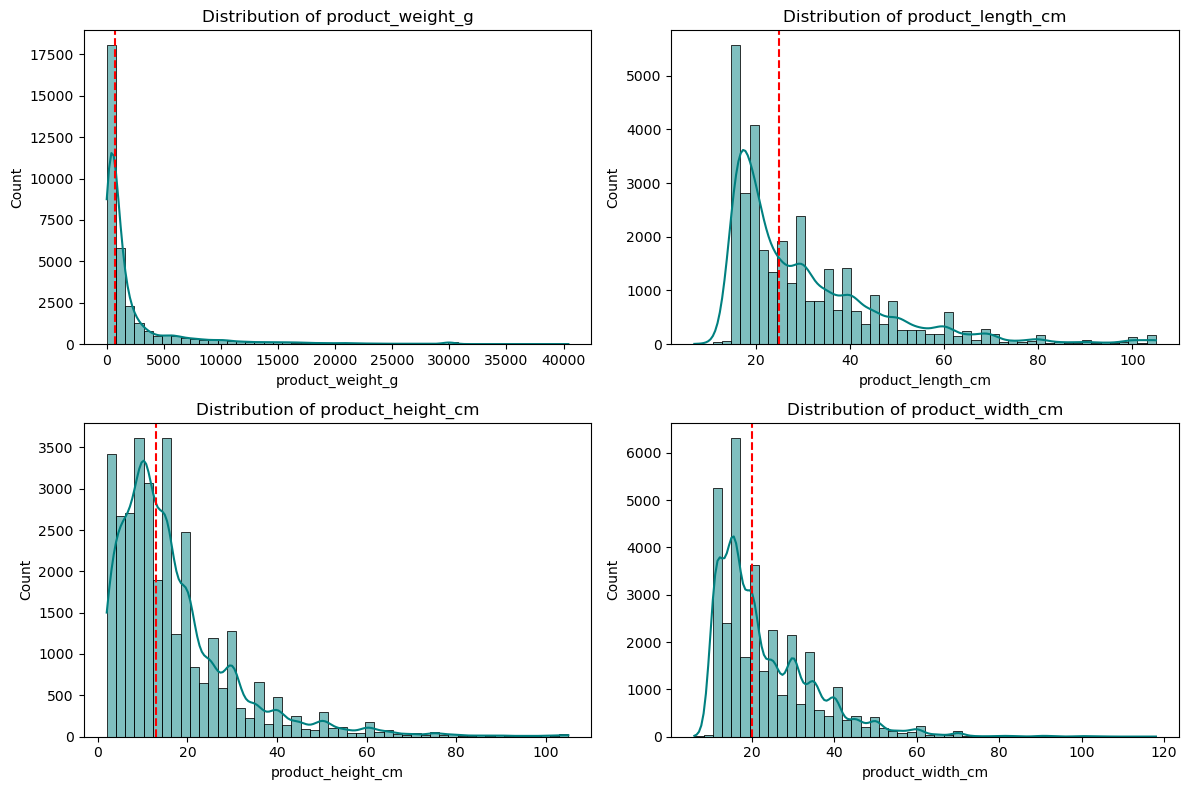

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), physical_cols):
    sns.histplot(products_valid[col], bins=50, kde=True, ax=ax, color='teal')
    ax.set_title(f'Distribution of {col}')
    ax.axvline(products_valid[col].median(), color='red', linestyle='--')
plt.tight_layout()
plt.show()


#### Key Observations

- Product physical attributes show highly uneven distributions, with most products concentrated at relatively smaller values.
- The distributions contain long right tails, indicating the presence of a smaller number of products with substantially larger physical dimensions or weight.
- These variations in physical characteristics may be relevant when investigating differences in freight costs.

### What product categories are most common?

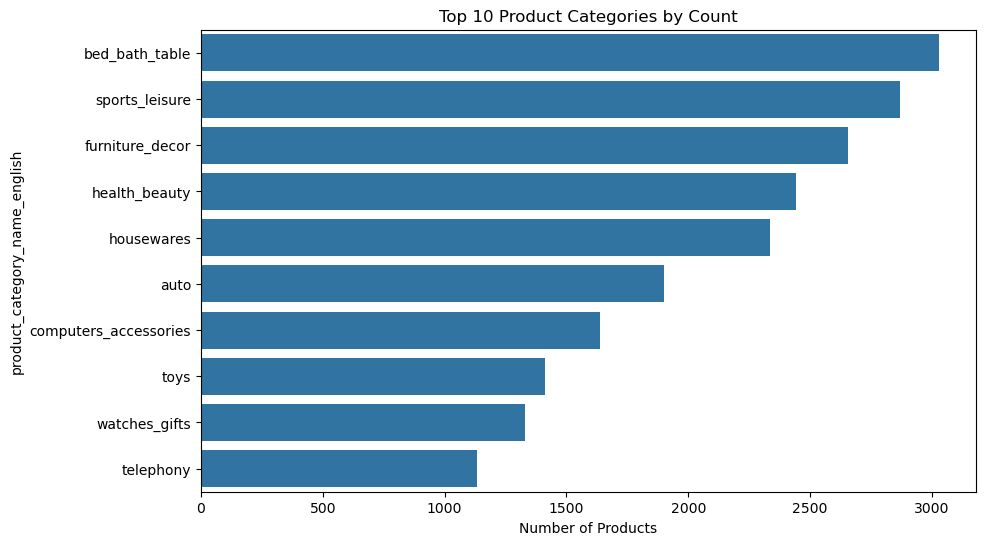

In [30]:
top_categories = products_cleaned['product_category_name_english'].value_counts().head(10)
plt.figure(figsize=(10,6))
sns.barplot(x=top_categories.values, y=top_categories.index, orient='h')
plt.title('Top 10 Product Categories by Count')
plt.xlabel('Number of Products')
plt.show()

#### Key Observation

- The product catalog contains a large number of distinct product categories.
- A relatively small number of categories account for a substantial share of the available products.
- The distribution of products across categories is uneven, with some categories containing considerably more products than others.

## Sellers Analysis 

### Where are sellers located?


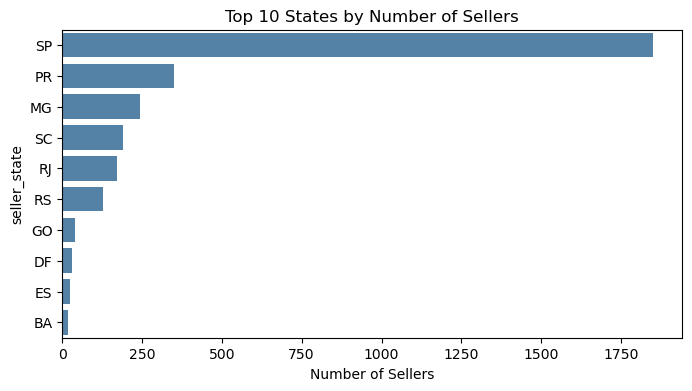

In [60]:
top_seller_states = sellers_cleaned['seller_state'].value_counts().head(10)
plt.figure(figsize=(8,4))
sns.barplot(x=top_seller_states.values, y=top_seller_states.index, orient='h', color='steelblue')
plt.title('Top 10 States by Number of Sellers')
plt.xlabel('Number of Sellers')
plt.show()

#### Key Observations

- Seller distribution is uneven across Brazilian states.
- A limited number of states contain a large proportion of the seller network.

### How geographically concentrated is the seller network?

In [50]:
seller_state_share = (
    sellers_cleaned['seller_state']
    .value_counts(normalize=True)
    .head(5)
    .sum()
)

print(f"Top 5 seller states share: {seller_state_share * 100:.2f}%")

Top 5 seller states share: 90.57%


#### Key Observation

- The top five states account for approximately 90% of all sellers.
- This indicates that the seller network is highly concentrated geographically.
 
 #### Business Insight

- A high concentration of sellers in a limited number of states may have implications for logistics network design and regional operations.
- The concentration also suggests that seller activity is not evenly distributed across the country.

## Geolocation Analysis 

In [ ]:
import unicodedata

def normalize_city(city):
    city = str(city).lower().strip()
    city = ''.join(
        c for c in unicodedata.normalize('NFKD', city)
        if not unicodedata.combining(c)
    )
    return city

geolocation_cleaned['city_normalized'] = (
    geolocation_cleaned['geolocation_city'].apply(normalize_city)
)

city_variations = (
    geolocation_cleaned
    .groupby('city_normalized')['geolocation_city']
    .nunique()
    .sort_values(ascending=False)
)

cities_with_variations = (
    geolocation_cleaned[
        geolocation_cleaned['city_normalized'].isin(
            city_variations[city_variations > 1].index
        )
    ]
    [['geolocation_city', 'city_normalized']]
    .drop_duplicates()
    .sort_values('city_normalized')
)

cities_with_variations

In [80]:
before = len(geolocation_cleaned)

geolocation_cleaned = geolocation_cleaned.drop_duplicates().copy()

after = len(geolocation_cleaned)

print(f"Removed rows: {before - after:,}")
print(f"Rows after deduplication: {after:,}")

Removed rows: 261,831
Rows after deduplication: 738,332


In [81]:
geolocation_cleaned.duplicated().sum()

np.int64(0)

In [74]:
geolocation_cleaned['geolocation_city'].nunique()

8011

In [75]:
geolocation_cleaned['city_normalized'].nunique()

5968

In [77]:
zip_record_counts = (
    geolocation_cleaned
    .groupby('geolocation_zip_code_prefix')
    .size()
)

zip_record_counts.describe()

count    19015.000000
mean        52.598633
std         72.057907
min          1.000000
25%         10.000000
50%         29.000000
75%         66.500000
max       1146.000000
dtype: float64

In [78]:
(zip_record_counts > 1).mean() * 100

np.float64(94.51485669208519)

#### Key Observation

- Multiple geographic records exist for the same ZIP code prefix.
- Therefore, a ZIP code prefix does not uniquely identify a single latitude-longitude coordinate in the geolocation table.
#### Business Insight

- Directly joining geolocation to customer or seller records using ZIP code prefix can create multiple matches and duplicate customer or seller records.
- Geographic joins therefore require an aggregation or coordinate-selection strategy before they are used for distance analysis.

In [79]:
geo_variability = (
    geolocation_cleaned
    .groupby('geolocation_zip_code_prefix')
    .agg(
        latitude_std=('geolocation_lat', 'std'),
        longitude_std=('geolocation_lng', 'std'),
        records=('geolocation_lat', 'size')
    )
)

geo_variability.sort_values(
    'records',
    ascending=False
).head(10)

,latitude_std,longitude_std,records
geolocation_zip_code_prefix,,,
24220,0.002605,0.005132,1146
24230,0.214799,0.154443,1102
38400,0.010084,0.010809,965
35500,0.012137,0.011558,907
11680,0.035212,0.051864,879
22631,0.001736,0.016258,832
30140,0.004143,0.007971,810
11740,0.023932,0.041863,788
38408,0.006884,0.012906,773


## Payment Analysis

In [88]:
payments_cleaned.sample(3)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19306,311f11836437bf8950d50701fb64fcbf,1,credit_card,4,781.51
91880,c8dc34e23d7065c2f4e1788710a65ecc,1,credit_card,8,635.75
19084,88fb1f364095174f013123c8a3781c31,1,credit_card,5,639.43


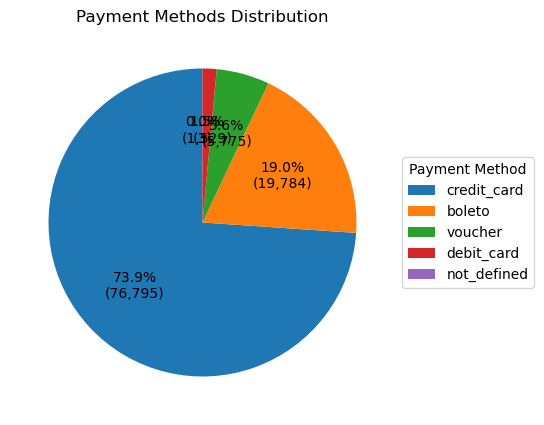

In [ ]:
payment_counts = payments_cleaned["payment_type"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(
    payment_counts,
    autopct=make_autopct(payment_counts),
    startangle=90
)
plt.legend(
    payment_counts.index,
    title="Payment Method",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)
plt.title("Payment Methods Distribution")
plt.show()